In [13]:
!pip install pyspark

In [14]:
import pandas as pd

data = {
    "Vehicle_ID": ["V001", "V002", "V003", "V004", "V005", "V006"],
    "Location": ["Road_A", "Road_A", "Road_B", "Road_A", "Road_B", "Road_C"],
    "Vehicle_Type": ["Car", "Bus", "Bike", "Car", "Car", "Truck"],
    "Speed": [18, 22, 45, 15, 50, 30],
    "Timestamp": [
        "2026-11-16 09:00:05",
        "2026-11-16 09:00:12",
        "2026-11-16 09:00:18",
        "2026-11-16 09:00:25",
        "2026-11-16 09:00:31",
        "2026-11-16 09:00:40"
    ]
}

df = pd.DataFrame(data)

df.to_csv("traffic.csv", index=False)

print("Traffic dataset created successfully!")
display(df)

Traffic dataset created successfully!


,Vehicle_ID,Location,Vehicle_Type,Speed,Timestamp
0,V001,Road_A,Car,18,2026-11-16 09:00:05
1,V002,Road_A,Bus,22,2026-11-16 09:00:12
2,V003,Road_B,Bike,45,2026-11-16 09:00:18
3,V004,Road_A,Car,15,2026-11-16 09:00:25
4,V005,Road_B,Car,50,2026-11-16 09:00:31
5,V006,Road_C,Truck,30,2026-11-16 09:00:40


In [36]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, count, avg, when, to_timestamp
)

spark = SparkSession.builder \
    .appName("RealTimeTrafficAnalysis") \
    .getOrCreate()

print("Spark started successfully!")

# Read traffic dataset
traffic = spark.read.csv(
    "traffic.csv",
    header=True,
    inferSchema=True
)

# Convert timestamp
traffic = traffic.withColumn(
    "Timestamp",
    to_timestamp(col("Timestamp"), "yyyy-MM-dd HH:mm:ss")
)

# Remove invalid records
traffic = traffic.filter(
    col("Vehicle_ID").isNotNull() &
    col("Location").isNotNull() &
    col("Speed").isNotNull() &
    (col("Speed") >= 0)
)

print("Traffic data:")
traffic.show()

# Calculate vehicle count and average speed
result = traffic.groupBy("Location").agg(
    count("Vehicle_ID").alias("Vehicle_Count"),
    avg("Speed").alias("Average_Speed")
)

# Identify congestion
result = result.withColumn(
    "Congestion_Level",
    when(col("Average_Speed") < 20, "High Congestion")
    .when(col("Average_Speed") <= 40, "Medium Congestion")
    .otherwise("Low Congestion")
)

print("TRAFFIC ANALYSIS RESULTS")
result.show(truncate=False)

spark.stop()

Spark started successfully!
Traffic data:
+----------+--------+------------+-----+-------------------+
|Vehicle_ID|Location|Vehicle_Type|Speed|          Timestamp|
+----------+--------+------------+-----+-------------------+
|      V001|  Road_A|         Car|   18|2026-11-16 09:00:05|
|      V002|  Road_A|         Bus|   22|2026-11-16 09:00:12|
|      V003|  Road_B|        Bike|   45|2026-11-16 09:00:18|
|      V004|  Road_A|         Car|   15|2026-11-16 09:00:25|
|      V005|  Road_B|         Car|   50|2026-11-16 09:00:31|
|      V006|  Road_C|       Truck|   30|2026-11-16 09:00:40|
+----------+--------+------------+-----+-------------------+

TRAFFIC ANALYSIS RESULTS
+--------+-------------+------------------+-----------------+
|Location|Vehicle_Count|Average_Speed     |Congestion_Level |
+--------+-------------+------------------+-----------------+
|Road_B  |2            |47.5              |Low Congestion   |
|Road_C  |1            |30.0              |Medium Congestion|
|Road_A  |3 

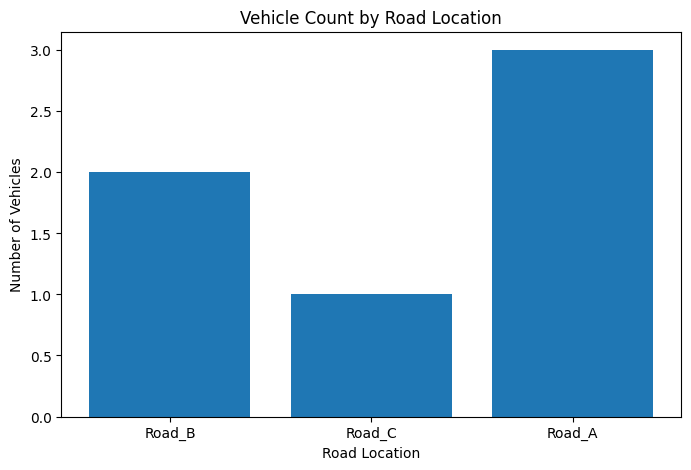

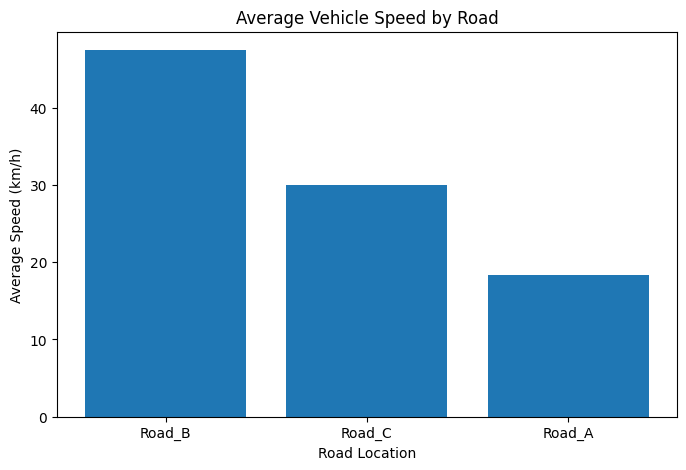

In [33]:
import matplotlib.pyplot as plt

# Since 'result' was created under a stopped Spark session,
# we use the active 'result_pd' DataFrame which is already loaded in the environment.

# Vehicle count graph
plt.figure(figsize=(8, 5))
plt.bar(result_pd["Location"], result_pd["Vehicle_Count"])
plt.title("Vehicle Count by Road Location")
plt.xlabel("Road Location")
plt.ylabel("Number of Vehicles")
plt.show()

# Average speed graph
plt.figure(figsize=(8, 5))
plt.bar(result_pd["Location"], result_pd["Average_Speed"])
plt.title("Average Vehicle Speed by Road")
plt.xlabel("Road Location")
plt.ylabel("Average Speed (km/h)")
plt.show()

In [32]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, avg, when, to_timestamp

spark = SparkSession.builder \
    .appName("RealTimeTrafficAnalysis") \
    .getOrCreate()

traffic = spark.read.csv(
    "traffic.csv",
    header=True,
    inferSchema=True
)

traffic = traffic.withColumn(
    "Timestamp",
    to_timestamp(col("Timestamp"), "yyyy-MM-dd HH:mm:ss")
)

traffic = traffic.filter(
    col("Vehicle_ID").isNotNull() &
    col("Location").isNotNull() &
    col("Speed").isNotNull() &
    (col("Speed") >= 0)
)

result = traffic.groupBy("Location").agg(
    count("Vehicle_ID").alias("Vehicle_Count"),
    avg("Speed").alias("Average_Speed")
)

result = result.withColumn(
    "Congestion_Level",
    when(col("Average_Speed") < 20, "High Congestion")
    .when(col("Average_Speed") <= 40, "Medium Congestion")
    .otherwise("Low Congestion")
)

result.show(truncate=False)

+--------+-------------+------------------+-----------------+
|Location|Vehicle_Count|Average_Speed     |Congestion_Level |
+--------+-------------+------------------+-----------------+
|Road_B  |2            |47.5              |Low Congestion   |
|Road_C  |1            |30.0              |Medium Congestion|
|Road_A  |3            |18.333333333333332|High Congestion  |
+--------+-------------+------------------+-----------------+



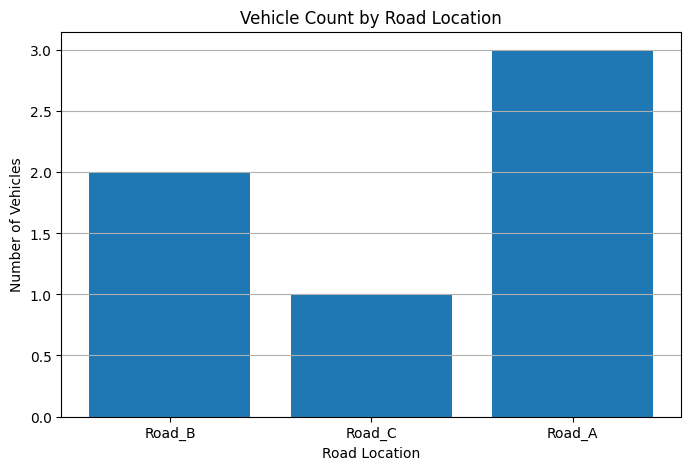

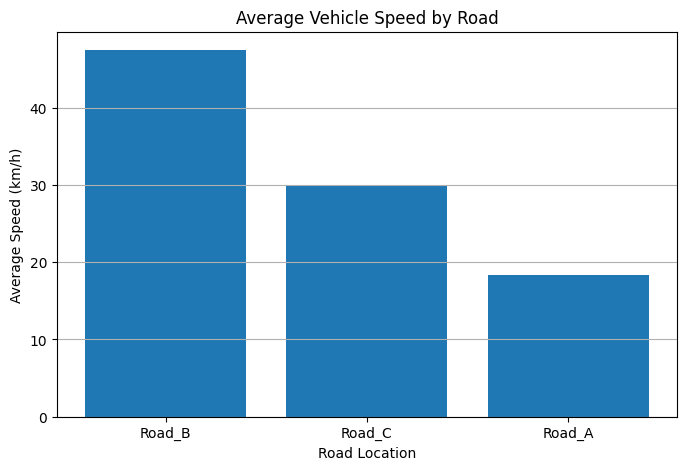

In [20]:
import matplotlib.pyplot as plt

result_pd = result.toPandas()

# Graph 1: Vehicle Count
plt.figure(figsize=(8, 5))
plt.bar(result_pd["Location"], result_pd["Vehicle_Count"])
plt.title("Vehicle Count by Road Location")
plt.xlabel("Road Location")
plt.ylabel("Number of Vehicles")
plt.grid(axis="y")
plt.show()

# Graph 2: Average Speed
plt.figure(figsize=(8, 5))
plt.bar(result_pd["Location"], result_pd["Average_Speed"])
plt.title("Average Vehicle Speed by Road")
plt.xlabel("Road Location")
plt.ylabel("Average Speed (km/h)")
plt.grid(axis="y")
plt.show()

In [30]:
result_pd.to_csv("traffic_analysis_results.csv", index=False)

print("Traffic analysis results saved successfully!")

Traffic analysis results saved successfully!


In [22]:
result_pd.to_csv("traffic_analysis_results.csv", index=False)

from google.colab import files
files.download("traffic_analysis_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import os

os.makedirs("traffic_stream_input", exist_ok=True)

print("Streaming input folder created successfully!")

Streaming input folder created successfully!


In [31]:
from pyspark.sql.types import (
    StructType, StructField, StringType, DoubleType
)
from pyspark.sql.functions import col, count, avg, when

spark = SparkSession.builder \
    .appName("RealTimeTrafficStreaming") \
    .getOrCreate()

schema = StructType([
    StructField("Vehicle_ID", StringType(), True),
    StructField("Location", StringType(), True),
    StructField("Vehicle_Type", StringType(), True),
    StructField("Speed", DoubleType(), True),
    StructField("Timestamp", StringType(), True)
])

stream_data = spark.readStream \
    .format("csv") \
    .option("header", "true") \
    .schema(schema) \
    .load("traffic_stream_input")

traffic_result = stream_data.groupBy("Location").agg(
    count("Vehicle_ID").alias("Vehicle_Count"),
    avg("Speed").alias("Average_Speed")
)

traffic_result = traffic_result.withColumn(
    "Congestion_Level",
    when(col("Average_Speed") < 20, "High Congestion")
    .when(col("Average_Speed") <= 40, "Medium Congestion")
    .otherwise("Low Congestion")
)

query = traffic_result.writeStream \
    .outputMode("complete") \
    .format("console") \
    .option("truncate", "false") \
    .option("checkpointLocation", "traffic_checkpoint") \
    .trigger(processingTime="5 seconds") \
    .start()

print("Traffic streaming started successfully!")

Traffic streaming started successfully!


In [26]:
import pandas as pd
import time

batch1 = {
    "Vehicle_ID": ["V101", "V102", "V103"],
    "Location": ["Road_A", "Road_B", "Road_A"],
    "Vehicle_Type": ["Car", "Bus", "Bike"],
    "Speed": [15, 45, 18],
    "Timestamp": [
        "2026-11-18 10:00:01",
        "2026-11-18 10:00:05",
        "2026-11-18 10:00:10"
    ]
}

pd.DataFrame(batch1).to_csv(
    "traffic_stream_input/batch1.csv", index=False
)

print("First traffic batch sent!")

First traffic batch sent!


In [27]:
batch2 = {
    "Vehicle_ID": ["V104", "V105", "V106"],
    "Location": ["Road_A", "Road_B", "Road_C"],
    "Vehicle_Type": ["Car", "Truck", "Bus"],
    "Speed": [12, 50, 30],
    "Timestamp": [
        "2026-11-18 10:01:01",
        "2026-11-18 10:01:05",
        "2026-11-18 10:01:10"
    ]
}

pd.DataFrame(batch2).to_csv(
    "traffic_stream_input/batch2.csv", index=False
)

print("Second traffic batch sent!")

Second traffic batch sent!


In [28]:
import pandas as pd

batch1 = {
    "Vehicle_ID": ["V101", "V102", "V103"],
    "Location": ["Road_A", "Road_B", "Road_A"],
    "Vehicle_Type": ["Car", "Bus", "Bike"],
    "Speed": [15, 45, 18],
    "Timestamp": [
        "2026-11-18 10:00:01",
        "2026-11-18 10:00:05",
        "2026-11-18 10:00:10"
    ]
}

pd.DataFrame(batch1).to_csv(
    "traffic_stream_input/batch1.csv",
    index=False
)

print("First traffic batch sent successfully!")

First traffic batch sent successfully!


In [35]:
batch2 = {
    "Vehicle_ID": ["V104", "V105", "V106"],
    "Location": ["Road_A", "Road_B", "Road_C"],
    "Vehicle_Type": ["Car", "Truck", "Bus"],
    "Speed": [12, 50, 30],
    "Timestamp": [
        "2026-11-18 10:01:01",
        "2026-11-18 10:01:05",
        "2026-11-18 10:01:10"
    ]
}

pd.DataFrame(batch2).to_csv(
    "traffic_stream_input/batch2.csv",
    index=False
)

print("Second traffic batch sent successfully!")

Second traffic batch sent successfully!


In [37]:
query.stop()

print("Traffic streaming stopped successfully!")

Py4JJavaError: An error occurred while calling o660.stop.
: java.lang.IllegalStateException: Cannot call methods on a stopped SparkContext.
This stopped SparkContext was created at:

org.apache.spark.api.java.JavaSparkContext.<init>(JavaSparkContext.scala:59)
java.base/jdk.internal.reflect.NativeConstructorAccessorImpl.newInstance0(Native Method)
java.base/jdk.internal.reflect.NativeConstructorAccessorImpl.newInstance(NativeConstructorAccessorImpl.java:75)
java.base/jdk.internal.reflect.DelegatingConstructorAccessorImpl.newInstance(DelegatingConstructorAccessorImpl.java:53)
java.base/java.lang.reflect.Constructor.newInstanceWithCaller(Constructor.java:502)
java.base/java.lang.reflect.Constructor.newInstance(Constructor.java:486)
py4j.reflection.MethodInvoker.invoke(MethodInvoker.java:247)
py4j.reflection.ReflectionEngine.invoke(ReflectionEngine.java:374)
py4j.Gateway.invoke(Gateway.java:238)
py4j.commands.ConstructorCommand.invokeConstructor(ConstructorCommand.java:80)
py4j.commands.Co

In [38]:
print("Query active:", query.isActive)
print("Spark session stopped:", spark.sparkContext._jsc is None)

Query active: False
Spark session stopped: True


In [39]:
print("Traffic streaming demonstration completed!")


Traffic streaming demonstration completed!
